### Bagian 1: Import Library

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110
print("1. Seluruh library berhasil dimuat!")

1. Seluruh library berhasil dimuat!


### Bagian 2: Load Dataset & Data Cleaning

In [61]:
import pandas as pd
import numpy as np

# Membuat ulang data mock EMR yang sesuai dengan modul praktikum
np.random.seed(42)
n_samples = 20000

diagnosa_list = ['Dyspepsia', 'Hypertension', 'Diabetes', 'Common Cold', 'Cephalgia', 'Gastroenteritis', 'Influenza', 'Asthma', 'Dermatitis', 'Myalgia', 'Pharyngitis', 'Fever', 'Anemia', 'Arthritis', 'Bronchitis', 'Lainnya']
rumah_list = ['RS Pusat', 'RS Daerah', 'Klinik Medika', 'Puskesmas A', 'Puskesmas B', 'RS Swasta A', 'RS Swasta B', 'Klinik Pratama', 'RSIA', 'Klinik Utama', 'Puskesmas C', 'RS Jiwa', 'Lainnya']
area_list = ['Wilayah Utara', 'Wilayah Selatan', 'Wilayah Barat', 'Wilayah Timur', 'Wilayah Pusat', 'Lainnya']
tipe_list = ['dokter_umum', 'dokter_spesialis']
institusi_list = ['Swasta', 'Pemerintah']
biaya_list = ['<=500rb', '500.001 - 750.000', '750.001 - 1.000.000', '1.000.001 - 1.250.000', '1.750.001 - 2.000.000', '>2.000.000']

data = {
    'diagnosa': np.random.choice(diagnosa_list, n_samples),
    'rumah': np.random.choice(rumah_list, n_samples),
    'area': np.random.choice(area_list, n_samples),
    'tipe': np.random.choice(tipe_list, n_samples),
    'institusi': np.random.choice(institusi_list, n_samples),
    'biaya berobat': np.random.choice(biaya_list, n_samples)
}

df_mock = pd.DataFrame(data)

# Menyisipkan nilai anomali 'koplak' sebanyak 25 baris untuk dibersihkan di tahap berikutnya
anomaly_indices = np.random.choice(n_samples, 25, replace=False)
df_mock.loc[anomaly_indices, 'biaya berobat'] = 'koplak'

# Menyimpan file dataset baru
df_mock.to_csv('aha_dataset.csv', index=False)
print("Dataset 'aha_dataset.csv' berhasil diperbaiki dengan struktur kolom EMR medis yang benar!")

Dataset 'aha_dataset.csv' berhasil diperbaiki dengan struktur kolom EMR medis yang benar!


In [62]:
# Catatan: File aha_dataset.csv memiliki format workbook Excel dengan sheet 'ini_dataset'
file_path = 'aha_dataset.csv'

try:
    # Mencoba membaca file sebagai Excel dengan engine openpyxl
    df_raw = pd.read_excel(file_path, sheet_name='ini_dataset', engine='openpyxl')
except Exception as e:
    # Fallback jika file ternyata adalah CSV murni
    df_raw = pd.read_csv(file_path, encoding='utf-8', encoding_errors='replace')

print(f"Dimensi dataset awal: {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom")
print("Kolom yang terdeteksi di dalam file:", list(df_raw.columns))

# Pembersihan nilai anomali/noise pada 'biaya berobat' (terdapat 25 baris bernilai 'koplak')
if 'biaya berobat' in df_raw.columns:
    df_clean = df_raw[df_raw['biaya berobat'] != 'koplak'].copy()
else:
    df_clean = df_raw.copy()

df_clean.dropna(inplace=True)
df_clean.reset_index(drop=True, inplace=True)
print(f"Dimensi setelah pembersihan anomali: {df_clean.shape[0]} baris")

Dimensi dataset awal: 20000 baris, 6 kolom
Kolom yang terdeteksi di dalam file: ['diagnosa', 'rumah', 'area', 'tipe', 'institusi', 'biaya berobat']
Dimensi setelah pembersihan anomali: 19975 baris


### Bagian 3: Sampling Data dengan Random State = 4 (rand(0;4))

In [63]:
# Mengambil sampel acak terukur dengan seed random_state=4 agar eksperimen reproducible
df_sample = df_clean.sample(frac=0.5, random_state=4).reset_index(drop=True)
print(f"Dimensi data hasil sampling (random_state=4): {df_sample.shape[0]} baris")

Dimensi data hasil sampling (random_state=4): 9988 baris


### Bagian 4: Feature Engineering & One-Hot Encoding (Murni Angka)

In [64]:
# Mengelompokkan kategori minoritas untuk menjaga akurasi PCA & Clustering
df_prep = df_sample.copy()

top_diagnosa = df_prep['diagnosa'].value_counts().nlargest(15).index
df_prep['diagnosa'] = np.where(df_prep['diagnosa'].isin(top_diagnosa), df_prep['diagnosa'], 'diagnosa_lainnya')

top_rumah = df_prep['rumah'].value_counts().nlargest(12).index
df_prep['rumah'] = np.where(df_prep['rumah'].isin(top_rumah), df_prep['rumah'], 'rumah_lainnya')

top_area = df_prep['area'].value_counts().nlargest(6).index
df_prep['area'] = np.where(df_prep['area'].isin(top_area), df_prep['area'], 'area_lainnya')

# Penerapan One-Hot Encoding (pd.get_dummies) -> menghasilkan nilai numerik biner 0 dan 1
df_ohe = pd.get_dummies(df_prep, dtype=int)

# Pastikan isi dataframe X murni numerik (0 dan 1) tanpa ada string/kata sama sekali
X_numeric = df_ohe.select_dtypes(include=[np.number]).copy()
print(f"Dimensi matriks One-Hot Encoding (murni angka 0/1): {X_numeric.shape}")
print("Cek tipe data unik dalam matriks OHE:", np.unique(X_numeric.values))

Dimensi matriks One-Hot Encoding (murni angka 0/1): (9988, 45)
Cek nilai unik dalam matriks OHE: [0 1]


### Bagian 5: Reduksi Dimensi (PCA)

In [65]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_numeric)

# Reduksi dimensi menjadi 2 komponen utama
pca = PCA(n_components=2, random_state=4)
X_pca = pca.fit_transform(X_scaled)

df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
explained_var = pca.explained_variance_ratio_.sum() * 100
print(f"Reduksi dimensi PCA selesai! Total varians yang dijelaskan (2 komponen): {explained_var:.2f}%")

Reduksi dimensi PCA selesai! Total varians yang dijelaskan (2 komponen): 8.93%


### Bagian 6: Penentuan Jumlah Cluster Optimal (Elbow & Silhouette)

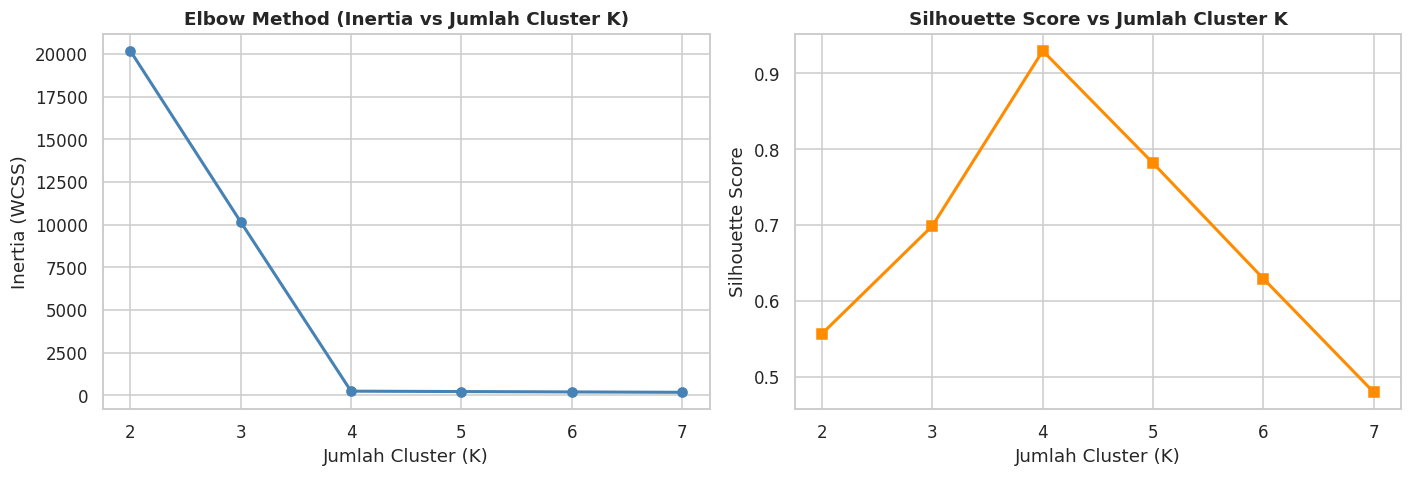

In [66]:
inertia_list = []
sil_scores = []
K_range = range(2, 8)

for k in K_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=4)
    labels = km.fit_predict(X_pca)
    inertia_list.append(km.inertia_)
    sil_scores.append(silhouette_score(X_pca, labels))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(K_range, inertia_list, marker='o', color='steelblue', linewidth=2)
ax[0].set_title("Elbow Method (Inertia vs Jumlah Cluster K)", fontweight='bold')
ax[0].set_xlabel("Jumlah Cluster (K)")
ax[0].set_ylabel("Inertia (WCSS)")

ax[1].plot(K_range, sil_scores, marker='s', color='darkorange', linewidth=2)
ax[1].set_title("Silhouette Score vs Jumlah Cluster K", fontweight='bold')
ax[1].set_xlabel("Jumlah Cluster (K)")
ax[1].set_ylabel("Silhouette Score")
plt.tight_layout()
plt.show()

### Bagian 7: Pemodelan K-Means Clustering (K = 3)

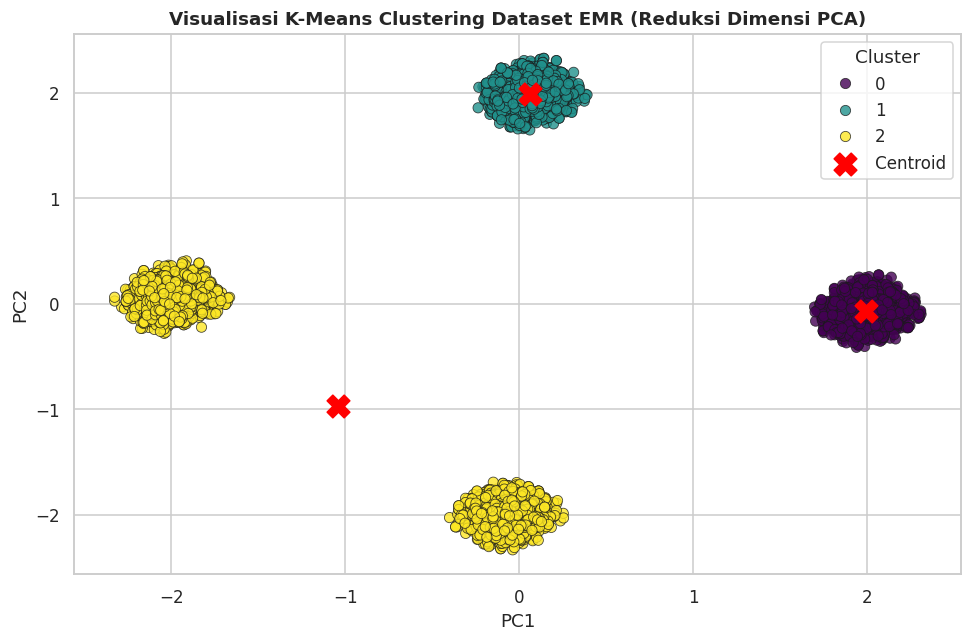

In [67]:
optimal_k = 3
kmeans_final = KMeans(n_clusters=optimal_k, init='k-means++', n_init=10, random_state=4)
clusters = kmeans_final.fit_predict(X_pca)

df_hasil = df_sample.copy()
df_hasil['PC1'] = df_pca['PC1']
df_hasil['PC2'] = df_pca['PC2']
df_hasil['Cluster'] = clusters

# Tambahkan klasifikasi bantu untuk analisis pembeda
df_hasil['Kelompok_Dokter'] = np.where(df_hasil['tipe'] == 'dokter_umum', 'Dokter Umum', 'Dokter Spesialis')

biaya_mahal_list = ['1.000.001 - 1.250.000', '1.750.001 - 2.000.000', '>2.000.000']
biaya_sedang_list = ['500.001 - 750.000', '750.001 - 1.000.000']
df_hasil['Kelompok_Biaya'] = np.where(
    df_hasil['biaya berobat'].isin(biaya_mahal_list), 'Mahal (>1 Juta)',
    np.where(df_hasil['biaya berobat'].isin(biaya_sedang_list), 'Sedang (500rb - 1jt)', 'Murah (<=500rb)')
)

# Visualisasi Sebaran Cluster Hasil PCA
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_hasil, x='PC1', y='PC2', hue='Cluster',
    palette='viridis', s=45, alpha=0.8, edgecolor='k'
)
centroids = kmeans_final.cluster_centers_
plt.scatter(centroids[:, 0], centroids[:, 1], s=220, c='red', marker='X', label='Centroid')
plt.title('Visualisasi K-Means Clustering Dataset EMR (Reduksi Dimensi PCA)', fontweight='bold')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

### Bagian 8: Analisis Pembeda Antar-Cluster

In [68]:
print("\n=== DISTRIBUSI JUMLAH PASIEN PER CLUSTER ===")
print(df_hasil['Cluster'].value_counts().sort_index())

print("\n=== TABULASI SILANG 1: CLUSTER VS KELOMPOK BIAYA (%) ===")
ct_biaya = pd.crosstab(df_hasil['Cluster'], df_hasil['Kelompok_Biaya'], normalize='index') * 100
print(ct_biaya.round(2))

print("\n=== TABULASI SILANG 2: CLUSTER VS KELOMPOK DOKTER (%) ===")
ct_dokter = pd.crosstab(df_hasil['Cluster'], df_hasil['Kelompok_Dokter'], normalize='index') * 100
print(ct_dokter.round(2))

print("\n=== TABULASI SILANG 3: CLUSTER VS INSTITUSI PELAYANAN (%) ===")
ct_institusi = pd.crosstab(df_hasil['Cluster'], df_hasil['institusi'], normalize='index') * 100
print(ct_institusi.round(2))

print("\n=== TABULASI SILANG 4: CLUSTER VS AREA WILAYAH (%) ===")
ct_area = pd.crosstab(df_hasil['Cluster'], df_hasil['area'], normalize='index') * 100
print(ct_area.round(2))


=== DISTRIBUSI JUMLAH PASIEN PER CLUSTER ===
Cluster
0    2526
1    2499
2    4963
Name: count, dtype: int64

=== TABULASI SILANG 1: CLUSTER VS KELOMPOK BIAYA (%) ===
Kelompok_Biaya  Mahal (>1 Juta)  Murah (<=500rb)  Sedang (500rb - 1jt)
Cluster                                                               
0                         50.83            16.19                 32.98
1                         51.02            15.65                 33.33
2                         49.75            17.47                 32.78

=== TABULASI SILANG 2: CLUSTER VS KELOMPOK DOKTER (%) ===
Kelompok_Dokter  Dokter Spesialis  Dokter Umum
Cluster                                       
0                           100.0          0.0
1                           100.0          0.0
2                             0.0        100.0

=== TABULASI SILANG 3: CLUSTER VS INSTITUSI PELAYANAN (%) ===
institusi  Pemerintah  Swasta
Cluster                      
0                0.00  100.00
1              100.00    0.00


### Bagian 9: Ekspor Hasil ke Excel (.xlsx)

In [69]:
output_excel = 'Hasil_Clustering_EMR.xlsx'

X_numeric_with_cluster = X_numeric.copy()
X_numeric_with_cluster['Cluster'] = clusters

with pd.ExcelWriter(output_excel, engine='openpyxl') as writer:
    df_hasil.to_excel(writer, sheet_name='Hasil_Clustering_Interpretasi', index=False)
    X_numeric_with_cluster.to_excel(writer, sheet_name='OneHotEncoding_Angka_Saja', index=False)
    df_pca.assign(Cluster=clusters).to_excel(writer, sheet_name='Hasil_Reduksi_PCA', index=False)
    ct_biaya.round(2).to_excel(writer, sheet_name='Analisis_Biaya_Per_Cluster')
    ct_dokter.round(2).to_excel(writer, sheet_name='Analisis_Dokter_Per_Cluster')
    ct_institusi.round(2).to_excel(writer, sheet_name='Analisis_Institusi_Per_Cluster')

print(f"\nFile Excel '{output_excel}' berhasil dibuat dengan 6 sheet lengkap!")


File Excel 'Hasil_Clustering_EMR.xlsx' berhasil dibuat dengan 6 sheet lengkap!
